# 02 · Feature Engineering
**Credora Finance — Credit Risk & Loan Approval Analytics Platform**

The real feature code lives in **`src/features.py`** (reusable by training and scoring). This notebook *imports* it,
shows what it produces, and checks that the features are correct and useful.

**Questions answered here**
1. What exactly goes into the model, and what is deliberately left out?
2. Are the joins safe (no duplicated loans, no leakage)?
3. Do the engineered features carry more signal than the raw columns they come from?
4. What does preprocessing do to the data?

Run `python src/data_load.py` first, then *Run All*.

## 1 · Setup

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 50, "display.width", 200)

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import features as F
from sklearn.metrics import roc_auc_score
from train import split_train_test

raw = F.load_raw()
df = F.build_features(raw)          # one row per DISBURSED loan
X, y, groups = F.get_xy(df)
print(f"Modelling table: {df.shape[0]:,} loans x {len(F.ALL_FEATURES)} features   |   default rate {y.mean() * 100:.1f}%")

Modelling table: 3,403 loans x 34 features   |   default rate 23.4%


## 2 · The modelling table
One row per disbursed loan: identifiers, the **target** (`loan_default`) and 34 features.

In [2]:
show = F.ID_COLS + [F.TARGET, "credit_score", "debt_to_income_ratio", "loan_to_income",
                    "emi_to_income", "tenure_years", "total_inflow", "net_cash_flow"]
df[show].head(8).round(3)

,application_id,customer_id,application_date,loan_default,credit_score,debt_to_income_ratio,loan_to_income,emi_to_income,tenure_years,total_inflow,net_cash_flow
0,APP800006,CUST102505,2022-07-22,0.0,614,0.640,1.986,0.122,3.907,93374.32,67254.77
1,APP800009,CUST102299,2024-01-19,0.0,795,0.158,0.081,0.112,6.683,187678.38,35134.60
2,APP800011,CUST101028,2024-03-27,0.0,664,1.074,2.819,0.211,0.548,60308.08,1809.13
3,APP800012,CUST102620,2022-08-23,1.0,627,0.833,2.090,0.263,8.731,18240.59,13170.60
4,APP800019,CUST102542,2022-09-13,0.0,651,0.601,4.471,0.116,6.992,0.00,-50252.23
5,APP800020,CUST100604,2024-02-28,0.0,766,0.376,0.506,0.274,3.680,122102.84,-2390.43
6,APP800021,CUST104834,2023-08-13,1.0,568,0.498,1.389,0.084,7.176,84139.23,74400.09
7,APP800022,CUST101020,2023-04-17,0.0,708,0.570,0.409,0.134,4.879,95510.84,38123.86


## 3 · Feature catalogue

In [3]:
for group, cols in F.FEATURE_GROUPS.items():
    print(f"{group} ({len(cols)}):  " + ", ".join(cols) + "\n")

Demographic (7):  age, dependents, years_at_residence, tenure_years, employment_type, residence_type, education

Credit bureau (10):  credit_score, credit_utilization_ratio, num_late_payments_30d, num_late_payments_90d, num_defaults_prior, bankruptcies, num_credit_inquiries_6m, num_open_accounts, total_credit_limit, total_outstanding_debt

Application (10):  annual_income, requested_amount, interest_rate, loan_term_months, debt_to_income_ratio, existing_emi, loan_to_income, emi_to_income, loan_type, collateral_flag

Transaction behaviour (7):  txn_count, total_inflow, total_outflow, net_cash_flow, emi_outflow, avg_balance, inflow_outflow_ratio



### Features we created (not in the raw tables)
| Feature | Formula | Why it should matter |
|---|---|---|
| `tenure_years` | (bureau snapshot date − `customer_since`) ÷ 365.25 | Longer relationship may signal stability |
| `loan_to_income` | `requested_amount` ÷ `annual_income` | Size of the ask relative to earnings |
| `emi_to_income` | `existing_emi` ÷ monthly income | Repayment burden already carried |
| `total_inflow`, `total_outflow`, `net_cash_flow` | Sum of credits / debits / difference, Jan–Jun 2024 | Cash-flow health |
| `emi_outflow`, `avg_balance`, `txn_count` | EMI-category debits, mean balance, number of transactions | Repayment behaviour and liquidity |
| `inflow_outflow_ratio` | `total_inflow` ÷ `total_outflow` (empty when outflow = 0) | Living within means |

*Tenure is measured at the bureau snapshot date because ~12% of customers have `customer_since` **after** their application
date, which would give negative tenure.*

### Deliberately excluded
| Column(s) | Reason |
|---|---|
| `approval_status`, `approved_amount`, `decision_date`, `disbursed_flag` | **Leakage** — only known after the decision |
| names, `email`, `phone`, `date_of_birth` | Personal data, not predictive |
| `applicant_monthly_income` | Exactly `annual_income ÷ 12` (redundant) |
| `debt_to_limit` (tried, then removed) | Identical to `credit_utilization_ratio` (see check below) |
| `oldest_account_age_months` | ~0.99 correlated with `age` (redundant) |
| `gender`, `marital_status`, `city`, `state` | Not model inputs (fairness; `city`/`state` also high-cardinality) |

### A feature we tried and removed: `debt_to_limit`
The PRD lists a debt-to-limit ratio. Let us check whether the bureau data already contains it.

In [4]:
c = raw["credit_history"]
ratio = c["total_outstanding_debt"] / c["total_credit_limit"]
print(f"Largest gap between  outstanding/limit  and  credit_utilization_ratio: {(ratio - c['credit_utilization_ratio']).abs().max():.4f}")
print("-> the two are the same number (the gap is just rounding), so a separate debt_to_limit would add nothing.")
print("   We use credit_utilization_ratio as the PRD's debt-to-limit measure.")

Largest gap between  outstanding/limit  and  credit_utilization_ratio: 0.0020
-> the two are the same number (the gap is just rounding), so a separate debt_to_limit would add nothing.
   We use credit_utilization_ratio as the PRD's debt-to-limit measure.


## 4 · Are the joins safe?
Transactions are many-per-customer. Joining them straight onto loans would **multiply** loan rows — the classic mistake.
`features.py` aggregates to one row per customer first and uses `validate="m:1"`, which makes pandas raise an error if a join
ever duplicates rows. Here is the unsafe version for comparison:

In [5]:
loans = raw["loan_applications"]
disb = loans[loans["disbursed_flag"] == 1]
unsafe = disb.merge(raw["transactions"], on="customer_id")
print(f"Disbursed loans: {len(disb):,}")
print(f"Naive join with raw transactions: {len(unsafe):,} rows  <- {len(unsafe) / len(disb):.1f}x too many, every loan repeated per transaction")

try:
    disb.merge(raw["transactions"], on="customer_id", validate="m:1")
except Exception as e:
    print(f"\nWith validate='m:1' pandas refuses: {type(e).__name__}")

print(f"\nOur feature table: {len(df):,} rows, application_id unique = {df['application_id'].is_unique}")

Disbursed loans: 3,403
Naive join with raw transactions: 27,508 rows  <- 8.1x too many, every loan repeated per transaction

With validate='m:1' pandas refuses: MergeError

Our feature table: 3,403 rows, application_id unique = True


## 5 · Data quality of the feature table

In [6]:
miss = X.isna().sum()
print("Missing values BEFORE imputation:", "none" if miss.sum() == 0 else miss[miss > 0].to_dict())
print(f"Infinite values: {int(np.isinf(X.select_dtypes('number')).sum().sum())}")
print(f"tenure_years range: {X['tenure_years'].min():.2f} to {X['tenure_years'].max():.2f}  (no negatives)")
print(f"inflow_outflow_ratio: {X['inflow_outflow_ratio'].isna().sum()} empty (customers with zero outflow)")
print(f"customers with NO credit-type transactions in 6 months: {(X['total_inflow'] == 0).sum()} loans")

banned = set(F.LEAKAGE_COLS + F.PII_COLS) & set(F.ALL_FEATURES)
print(f"\nLeakage / PII columns inside the feature list: {banned or 'none'}")

Missing values BEFORE imputation: {'inflow_outflow_ratio': 3}
Infinite values: 0
tenure_years range: 0.00 to 10.99  (no negatives)
inflow_outflow_ratio: 3 empty (customers with zero outflow)
customers with NO credit-type transactions in 6 months: 510 loans

Leakage / PII columns inside the feature list: none


## 6 · Which features carry signal?
**Univariate ROC-AUC**: how well a *single* feature ranks defaulters above repaid loans (0.5 = useless, 1.0 = perfect;
direction ignored). It ignores interactions, so it is a screening tool, not the final word.

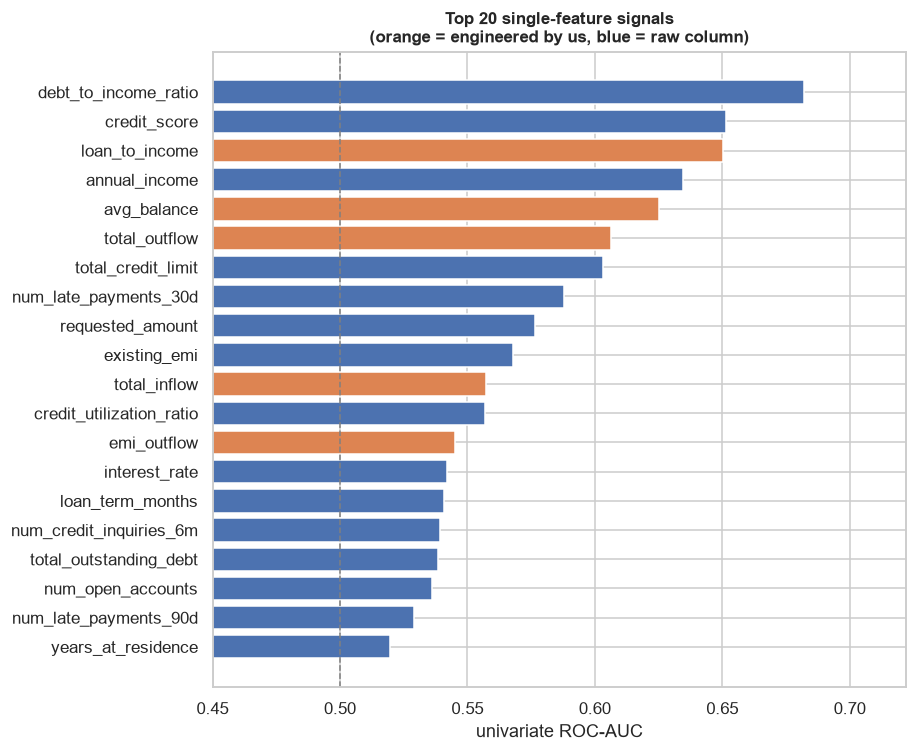

,feature,auc,direction,group,engineered
18,debt_to_income_ratio,0.682,higher -> more default,Application,False
4,credit_score,0.651,higher -> less default,Credit bureau,False
20,loan_to_income,0.650,higher -> more default,Application,True
14,annual_income,0.634,higher -> less default,Application,False
27,avg_balance,0.625,higher -> less default,Transaction behaviour,True
24,total_outflow,0.606,higher -> less default,Transaction behaviour,True
12,total_credit_limit,0.603,higher -> less default,Credit bureau,False
6,num_late_payments_30d,0.588,higher -> more default,Credit bureau,False
15,requested_amount,0.576,higher -> more default,Application,False
19,existing_emi,0.568,higher -> less default,Application,False


In [7]:
engineered = {"tenure_years", "loan_to_income", "emi_to_income", "total_inflow", "total_outflow",
              "net_cash_flow", "emi_outflow", "avg_balance", "txn_count", "inflow_outflow_ratio"}
group_of = {c: g for g, cols in F.FEATURE_GROUPS.items() for c in cols}

rows = []
for c in F.NUMERIC_FEATURES + F.BINARY_FEATURES:
    s = X[c]; m = s.notna()
    auc = roc_auc_score(y[m], s[m])
    rows.append((c, max(auc, 1 - auc), "higher -> more default" if auc > 0.5 else "higher -> less default",
                 group_of.get(c, "Application"), c in engineered))
uni = pd.DataFrame(rows, columns=["feature", "auc", "direction", "group", "engineered"]).sort_values("auc", ascending=False)

top = uni.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh(top["feature"], top["auc"], color=["#DD8452" if e else "#4C72B0" for e in top["engineered"]])
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlim(0.45, top["auc"].max() + 0.04); ax.set_xlabel("univariate ROC-AUC")
ax.set_title("Top 20 single-feature signals\n(orange = engineered by us, blue = raw column)")
plt.tight_layout(); plt.show()
uni.head(10).round(3)

### Did engineering beat the raw columns it came from?

In [8]:
pairs = [("loan_to_income", "requested_amount"), ("emi_to_income", "existing_emi"),
         ("net_cash_flow", "total_inflow")]
a = uni.set_index("feature")["auc"]
comp = pd.DataFrame([{"engineered": e, "AUC": a[e], "raw column": r, "raw AUC": a[r],
                      "gain": a[e] - a[r]} for e, r in pairs]).round(3)
comp

,engineered,AUC,raw column,raw AUC,gain
0,loan_to_income,0.650,requested_amount,0.576,0.074
1,emi_to_income,0.512,existing_emi,0.568,-0.056
2,net_cash_flow,0.506,total_inflow,0.557,-0.051


**Honest reading.** Only `loan_to_income` clearly beats the raw column it came from: a large loan means little without
knowing the borrower's income. `emi_to_income` and `net_cash_flow` are *weaker* on their own than their sources. A single-feature
score is only a screening tool, though, so we now test what really matters: does each feature group improve the actual
model? (Logistic Regression, 5-fold customer-grouped CV, averaged over 3 random seeds.)

In [9]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def cv_auc(drop):
    num = [c for c in F.NUMERIC_FEATURES if c not in drop]
    pre = ColumnTransformer([
        ("n", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
        ("c", Pipeline([("i", SimpleImputer(strategy="constant", fill_value="Unknown")),
                        ("o", OneHotEncoder(handle_unknown="ignore"))]), F.CATEGORICAL_FEATURES),
        ("b", "passthrough", F.BINARY_FEATURES)])
    model = Pipeline([("p", pre), ("m", LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"))])
    scores = [cross_val_score(model, X, y, cv=StratifiedGroupKFold(5, shuffle=True, random_state=s),
                              groups=groups, scoring="roc_auc").mean() for s in (1, 2, 3)]
    return np.mean(scores), np.std(scores)

abl = []
for label, drop in [("All 34 features", []),
                    ("Without the 7 transaction features", F.TRANSACTION),
                    ("Without the 2 new ratios (loan_to_income, emi_to_income)", ["loan_to_income", "emi_to_income"]),
                    ("Without tenure_years", ["tenure_years"])]:
    m, sd = cv_auc(drop); abl.append((label, m, sd))
abl = pd.DataFrame(abl, columns=["feature set", "CV ROC-AUC", "seed-to-seed std"]).round(4)
abl["change vs all"] = (abl["CV ROC-AUC"] - abl.loc[0, "CV ROC-AUC"]).round(4)
abl

,feature set,CV ROC-AUC,seed-to-seed std,change vs all
0,All 34 features,0.7356,0.0016,0.0000
1,Without the 7 transaction features,0.7368,0.0016,0.0012
2,"Without the 2 new ratios (loan_to_income, emi_...",0.7355,0.0018,-0.0001
3,Without tenure_years,0.7360,0.0017,0.0004


**No feature group shows a measurable lift.** Every change is at most about 0.001, smaller than the seed-to-seed spread
(about 0.0016), which counts as noise. Three honest takeaways:
- **The signal is concentrated in a few raw features** (debt-to-income, credit score, income). The model already has the
  raw ingredients, so ratios built from them add little. `loan_to_income` is a strong *single* signal (section above) but
  gives nothing extra once income and loan amount are both in the model.
- **Transaction features add no measurable lift.** With only about 8 transactions per customer, and `avg_balance` mostly
  restating income (correlation 0.94), this is plausible.
- **We keep them all** because the PRD asks for these features, they are interpretable and they do no harm. We simply do not
  claim they improve the model. Fewer features would be an equally defensible choice.

## 7 · Engineered features: repaid vs defaulted

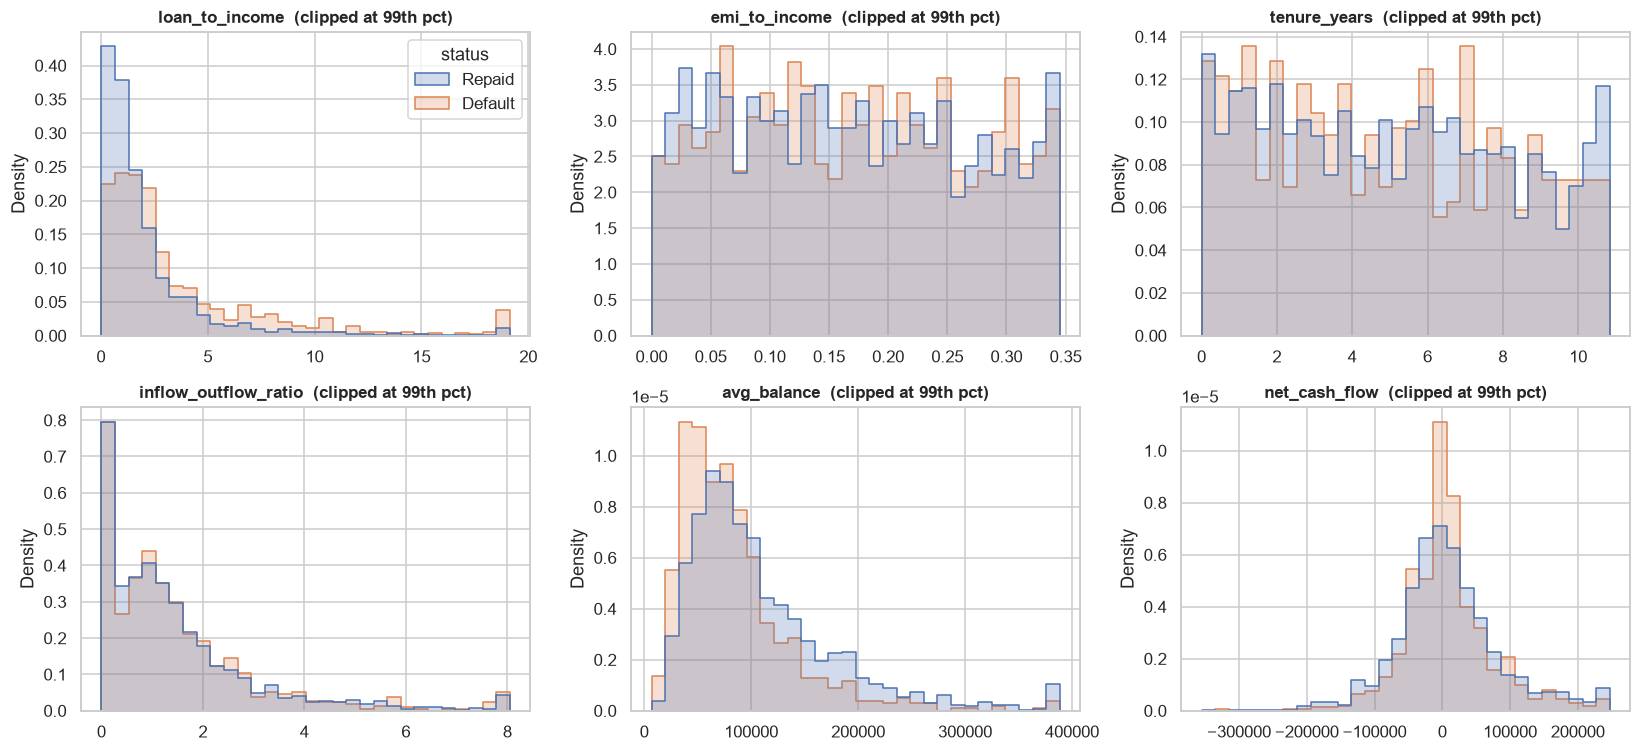

In [10]:
d = df.assign(status=y.map({0: "Repaid", 1: "Default"}))
cols = ["loan_to_income", "emi_to_income", "tenure_years", "inflow_outflow_ratio", "avg_balance", "net_cash_flow"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), cols):
    clip = d[c].quantile(0.99)
    sns.histplot(data=d.assign(v=d[c].clip(upper=clip)), x="v", hue="status", hue_order=["Repaid", "Default"],
                 stat="density", common_norm=False, element="step", bins=30,
                 palette={"Repaid": "#4C72B0", "Default": "#DD8452"}, ax=ax, legend=(c == cols[0]))
    ax.set_title(c + "  (clipped at 99th pct)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 8 · Redundant features
Highly correlated pairs add noise for linear models and dilute importance scores. We already removed the two worst
(monthly income, account age). What is left?

In [11]:
corr = X[F.NUMERIC_FEATURES].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
red = upper[upper > 0.85].sort_values(ascending=False).round(3).rename("abs correlation")
print("Remaining pairs with |correlation| > 0.85:")
print(red.to_string() if len(red) else "none")

Remaining pairs with |correlation| > 0.85:
annual_income  avg_balance    0.943


`annual_income` and `avg_balance` are ~0.94 correlated: average balance largely restates income. We **keep** both: tree
models are unaffected, and Logistic Regression is regularised (its `C` parameter is tuned in `train.py`). It also explains why
the transaction features add little beyond income.

## 9 · What the preprocessing pipeline does
`make_preprocessor()` is fitted on the **training** loans only, then applied to test data, so test information never
leaks into imputation or scaling. Customers are split between train and test as whole groups.

In [12]:
tr, te = split_train_test(X, y, groups)
pre = F.make_preprocessor(scale=True).fit(X.iloc[tr])
Xtr_t, Xte_t = pre.transform(X.iloc[tr]), pre.transform(X.iloc[te])

print(f"Before: {X.shape[1]} columns   ->   After: {Xtr_t.shape[1]} columns  (categoricals one-hot encoded)")
print(f"Missing values in test set: before {int(X.iloc[te].isna().sum().sum())}  ->  after {int(Xte_t.isna().sum().sum())}")
print("\nStandardised numeric columns (train): mean ~ 0, std ~ 1")
print(Xtr_t[["credit_score", "debt_to_income_ratio", "annual_income"]].agg(["mean", "std"]).round(3))

onehot = [c for c in Xtr_t.columns if any(c.startswith(k + "_") for k in F.CATEGORICAL_FEATURES)]
print(f"\n{len(onehot)} one-hot columns, e.g.: {onehot[:6]}")
print("\nShared customers between train and test:", len(set(groups.iloc[tr]) & set(groups.iloc[te])))

Before: 34 columns   ->   After: 50 columns  (categoricals one-hot encoded)
Missing values in test set: before 0  ->  after 0

Standardised numeric columns (train): mean ~ 0, std ~ 1
      credit_score  debt_to_income_ratio  annual_income
mean          -0.0                  -0.0           -0.0
std            1.0                   1.0            1.0

20 one-hot columns, e.g.: ['loan_type_Auto', 'loan_type_Business', 'loan_type_Education', 'loan_type_Gold', 'loan_type_Home', 'loan_type_Personal']

Shared customers between train and test: 0


## 10 · Summary and hand-off
| Check | Result |
|---|---|
| Rows / unique loans | 3,403, no duplicates (join guarded by `validate="m:1"`) |
| Leakage and PII columns in features | none |
| Strongest single signals | debt-to-income, credit score, loan-to-income, income (see chart above) |
| Redundant columns | removed (monthly income, account age, and our own `debt_to_limit`, which duplicated credit utilisation) |
| Do transaction features help? | See the ablation in section 6; kept because the PRD asks for them |
| Preprocessing | median imputation, scaling for Logistic Regression only, one-hot for categoricals, fitted on train only |

**Next:** `src/train.py` tunes four models on this table, and `03_modeling.ipynb` walks through the results.